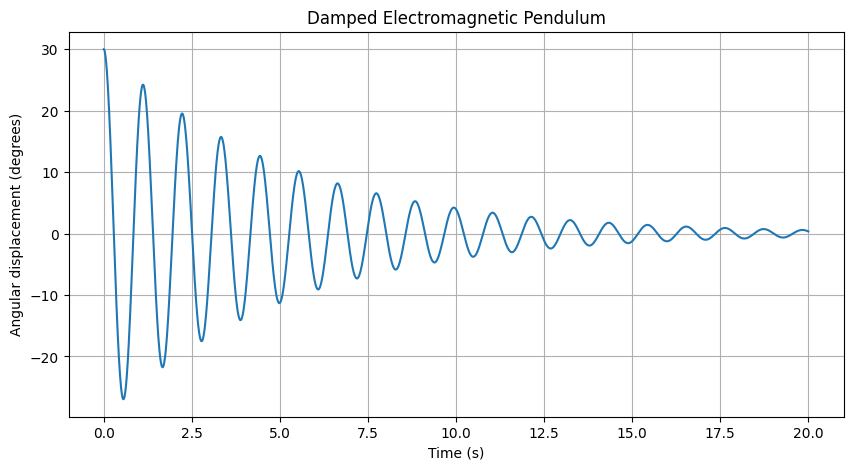

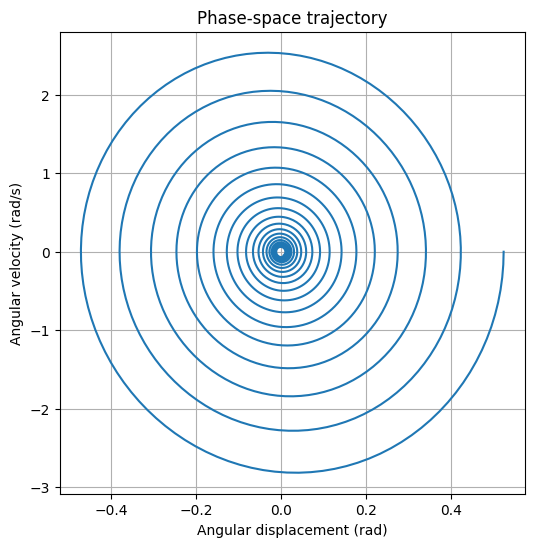

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import pandas as pd

# Physical parameters
m = 0.05       # mass of magnet (kg)
L = 0.30       # pendulum length (m)
g = 9.81       # gravitational acceleration (m/s^2)
c = 0.02       # effective eddy-current damping (kg/s)

# Initial conditions
theta0 = np.radians(30)
omega0 = 0.0

# Time interval
t_start = 0
t_end = 20
t_eval = np.linspace(t_start, t_end, 2000)

# Equations of motion
def pendulum(t, y):
    theta, omega = y

    dtheta = omega

    domega = (
        -(g / L) * np.sin(theta)
        -(c / m) * np.cos(theta)**2 * omega
    )

    return [dtheta, domega]

# Numerical integration
solution = solve_ivp(
    pendulum,
    [t_start, t_end],
    [theta0, omega0],
    t_eval=t_eval,
    method="RK45",
    rtol=1e-9,
    atol=1e-11
)

theta = solution.y[0]
omega = solution.y[1]
t = solution.t

# Plot angular displacement
plt.figure(figsize=(10, 5))
plt.plot(t, np.degrees(theta))
plt.xlabel("Time (s)")
plt.ylabel("Angular displacement (degrees)")
plt.title("Damped Electromagnetic Pendulum")
plt.grid()
plt.savefig("angular_displacement.png")
plt.show()

# Plot phase space
plt.figure(figsize=(6, 6))
plt.plot(theta, omega)
plt.xlabel("Angular displacement (rad)")
plt.ylabel("Angular velocity (rad/s)")
plt.title("Phase-space trajectory")
plt.grid()
plt.savefig("phase_space.png")
plt.show()

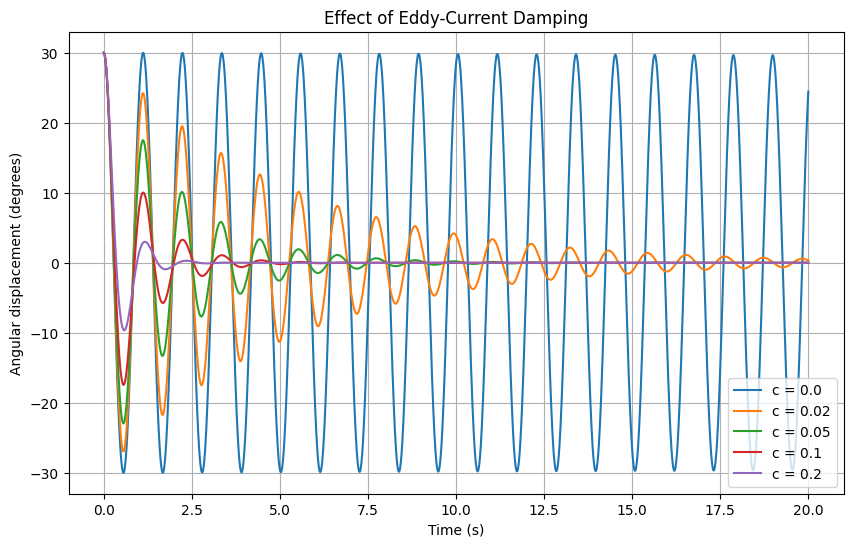

In [12]:
damping_values = [0.0, 0.02, 0.05, 0.1, 0.2]

plt.figure(figsize=(10, 6))

for c in damping_values:

    def pendulum(t, y):
        theta, omega = y

        return [
            omega,
            -(g / L) * np.sin(theta)
            -(c / m) * np.cos(theta)**2 * omega
        ]

    solution = solve_ivp(
        pendulum,
        [0, 20],
        [theta0, omega0],
        t_eval=t_eval
    )

    plt.plot(
        solution.t,
        np.degrees(solution.y[0]),
        label=f"c = {c}"
    )

plt.xlabel("Time (s)")
plt.ylabel("Angular displacement (degrees)")
plt.title("Effect of Eddy-Current Damping")
plt.legend()
plt.grid()
plt.savefig("effect_of_damping.png")
plt.show()

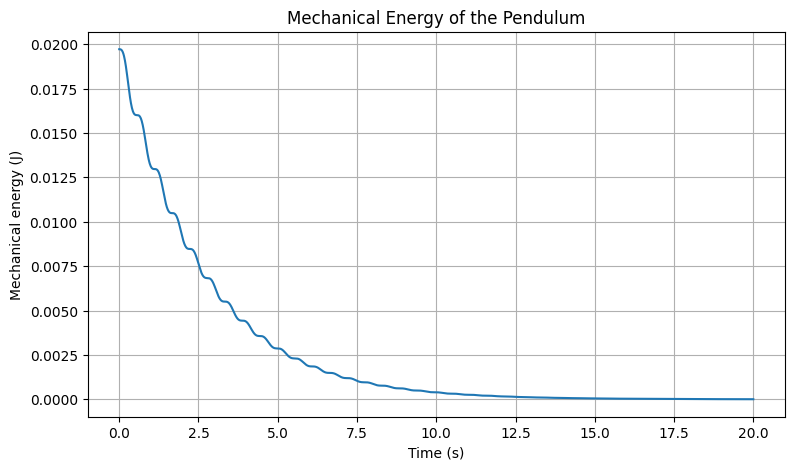

In [13]:
# Mechanical energy
E = 0.5 * m * L**2 * omega**2 + m * g * L * (1 - np.cos(theta))

plt.figure(figsize=(9, 5))
plt.plot(t, E)
plt.xlabel("Time (s)")
plt.ylabel("Mechanical energy (J)")
plt.title("Mechanical Energy of the Pendulum")
plt.grid()
plt.savefig("mechanical_energy.png")
plt.show()

In [14]:
# Initial and final mechanical energy
E_initial = E[0]
E_final = E[-1]

print(f"Initial energy: {E_initial:.6e} J")
print(f"Final energy:   {E_final:.6e} J")

energy_lost = E_initial - E_final

print(f"Energy dissipated: {energy_lost:.6e} J")
print(f"Fraction dissipated: {energy_lost/E_initial:.6%}")

Initial energy: 1.971436e-02 J
Final energy:   7.393344e-06 J
Energy dissipated: 1.970697e-02 J
Fraction dissipated: 99.962498%


In [15]:
from google.colab import files
files.download('angular_displacement.png')
files.download('phase_space.png')
files.download('effect_of_damping.png')
files.download('mechanical_energy.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>